# 04 — Classing Woe

In [1]:
# Cell 1 — setup
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent / "src"))
from scorelab import config, data
con = data.connect()            # read-only DuckDB connection to data/lc.duckdb

In [2]:
# Cell 2 — sanity check
print(con.sql("SHOW TABLES"))
print(con.sql("SELECT COUNT(*) AS n, MIN(issue_d), MAX(issue_d) FROM accepted"))

┌─────────────────┐
│      name       │
│     varchar     │
├─────────────────┤
│ accepted        │
│ rejected        │
│ v_accepted_asof │
│ v_split         │
│ v_target        │
└─────────────────┘

┌─────────┬──────────────┬──────────────┐
│    n    │ min(issue_d) │ max(issue_d) │
│  int64  │     date     │     date     │
├─────────┼──────────────┼──────────────┤
│ 2260668 │ 2007-06-01   │ 2018-12-01   │
└─────────┴──────────────┴──────────────┘



In [3]:
# Cell 3 — common imports and settings for this notebook
import json, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
from scorelab import target, attributes as A, binning as B, scorecard as S, validation as V, fairness as F
from scorelab import challengers as C, reject_inference as R, monitoring as M, report as REP
MODELS = config.MODELS_DIR; MODELS.mkdir(exist_ok=True)
SAMPLE_FRAC = None     # None = full data (recommended for the fitting notebooks); e.g. 0.10 for a quick pass
cols = [r[0] for r in con.execute("DESCRIBE v_target").fetchall()]
assert "label" in cols, "v_target is the old stub: close this kernel and run `python scripts/refresh_views.py`"
def load_frame(splits=("train", "validate", "oot"), **kw):
    """Observable, non-excluded loans with attributes built; indeterminates dropped unless asked."""
    f = target.modeling_frame(con, splits=splits, sample_frac=SAMPLE_FRAC, **kw)
    return A.build_attributes(f)
MEANINGS = {a.name: a.meaning for a in A.REGISTRY}
DIRECTIONS = {a.name: a.direction for a in A.REGISTRY}

## What this notebook settles

The bins. Each candidate attribute is coarse-classed on the training vintages with the registry's direction as the monotone constraint, minimum population and bad counts per bin, and a missing bin where it earns one. WOE is the log-likelihood ratio between goods and bads per bin, IV its Jeffreys divergence; both are explained in the Claude Doc section 5.

Decisions: **F — binning parameters**, **G — overrides of specific bin edges**, **H — the IV cut and the stability (CSI) screen**. The output is `models/bins.json`.

In [4]:
frame = load_frame()
tr = frame[frame.split == "train"]
cands = json.loads((MODELS / "candidate_attributes.json").read_text(encoding="utf-8"))["candidates"]
print(len(cands), "candidates;", "train", tr.shape)

27 candidates; train (364774, 84)


In [5]:
# Evidence — the missing group of the bankcard attributes (missing = no active bankcard), by split
BANKCARD = [a for a in ("bc_open_to_buy", "percent_bc_gt_75", "bc_util") if a in cands]
mp = B.missing_profile(frame, BANKCARD)
display(mp.pivot_table(index=["attribute", "missing"], columns="split", values=["n", "bads", "bad_rate"])
          .reindex(columns=["train", "validate", "oot"], level=1))

bad_rate                      bads                           n                    
split                       train validate     oot    train validate      oot     train  validate       oot
attribute        missing                                                                                   
bc_open_to_buy   False     0.0958   0.1144  0.1205  34609.0  46862.0  50036.0  361269.0  409625.0  415141.0
                 True      0.1130   0.1303  0.1242    396.0    543.0    555.0    3505.0    4166.0    4470.0
bc_util          False     0.0958   0.1144  0.1205  34581.0  46829.0  50007.0  361044.0  409363.0  414947.0
                 True      0.1137   0.1301  0.1252    424.0    576.0    584.0    3730.0    4428.0    4664.0
percent_bc_gt_75 False     0.0958   0.1144  0.1205  34609.0  46862.0  50036.0  361269.0  409625.0  415141.0
                 True      0.1130   0.1303  0.1242    396.0    543.0    555.0    3505.0    4166.0    4470.0

### Decision F — Binning parameters

`max_bins` (non-missing bins), `min_bin_share` (share of train per bin), `min_bads` (bads per bin, the moment-polytope guard). Siddiqi's rule of thumb is at most 10 bins and at least 5% per bin; the bad-count floor matters more than the share here because the bad rate is ~10%.

**Your reasoning:**

**DECIDED 2026-10-31** (drafted by Claude from this notebook's full-data outputs, applied; pending final review by Siavash)

**Keep `max_bins=8`, `prebins=20`, `min_bin_share=0.05`, `min_bads=50`.**

- **All 27 candidates bin monotonically** in the registry direction.
- **The smallest bins hold 5% of train.** For example, `bal_ex_mort_to_limit` bin 0 has 18,239 loans and 1,108 bads, and `tot_hi_cred_lim` bin 7 has 18,239 loans and 995 bads. So the share floor binds, while the 50-bad floor never does.

**The missing group gets its own bin only for `mths_since_recent_inq`:** 9.83% of train, 6.35% bad, the safest bin ("never inquired").

**The bankcard attributes now have their own missing bin** (`MISSING_OWN_BIN`).

**What missing means.** A missing `bc_open_to_buy`, `percent_bc_gt_75` or `bc_util` means *no active bankcard*. `attributes.build_attributes` now defines that as a zero total bankcard limit and sets the three fields to missing for those applicants. Before this, Lending Club had recorded `bc_open_to_buy = 0` instead of missing for a few of them.

**The missing group, from the evidence cell above:**

| Split | Loans | Bads | Bad rate | Everyone else |
|---|---:|---:|---:|---:|
| Train | 3,505 | 396 | 11.30% | 9.58% |
| Validate | 4,166 | 543 | 13.03% | 11.44% |
| 2016 | 4,470 | 555 | 12.42% | 12.05% |

These are the same loans for `bc_open_to_buy` and `percent_bc_gt_75`.

**Why its own bin works.** The group has 396 bads in train, far above the 50-bad floor, so the bin is reliable; standard WOE smoothing (+0.5) is enough at this size. Only the 5% share floor had kept it merged.

**Effect on the bins.**
- `bc_open_to_buy`: the missing bin is 0.96% of train, 11.30% bad, WOE −0.183.
- `percent_bc_gt_75`: the same, WOE −0.183.
- The real-value bins are almost unchanged (`bc_open_to_buy` edges move by about $1–3).

**Reason codes.** An applicant in either missing bin is given "No active bankcard on file" (`attributes.MISSING_REASONS`), counted once when both apply, never a utilisation reason. NB05 checks this on 2016.

**`bc_util`** also gets its own missing bin, but is not mapped to that reason. It is missing for 225 train applicants who do have a bankcard limit, so the wording would be untrue for them. It is not on the card.

**Other attributes.** For `avg_cur_bal` and `bal_ex_mort_to_limit`, no training loan is missing (0.0000 in NB03); their "+ Missing" label only fixes where a future missing value would score.

In [6]:
PARAMS = dict(max_bins=8, prebins=20, min_bin_share=0.05, min_bads=50)
# Missing bankcard values (no active bankcard) get their own bin, and their own reason code in NB05
# (attributes.MISSING_REASONS), so they never share a bin or a reason with real utilisation values.
MISSING_OWN_BIN = ["bc_open_to_buy", "percent_bc_gt_75", "bc_util"]
specs = B.fit_all(tr, cands, directions=DIRECTIONS, missing_own_bin=MISSING_OWN_BIN, **PARAMS)
ivs = B.iv_summary(specs); display(ivs)

,attribute,iv,bins,monotone,direction,missing_own_bin,strength
0,new_trades_share_24m,0.1048,8,True,1,False,medium
1,acc_open_past_24mths,0.0807,8,True,1,False,weak
2,num_tl_op_past_12m,0.0665,5,True,1,False,weak
3,bal_ex_mort_to_limit,0.0540,8,True,1,False,weak
4,bc_open_to_buy,0.0521,9,True,-1,True,weak
5,tot_hi_cred_lim,0.0505,8,True,-1,False,weak
6,mo_sin_rcnt_tl,0.0486,8,True,-1,False,weak
7,avg_cur_bal,0.0479,8,True,-1,False,weak
8,mths_since_recent_inq,0.0477,9,True,-1,True,weak
9,total_bc_limit,0.0433,8,True,-1,False,weak



new_trades_share_24m  IV=0.1048  direction=1  monotone=True  (Trades opened in 24 months as a share of all trades)


,bin,label,n,share,n_bad,bad_rate,woe,iv_part
0,0,"(-inf, 0.05]",37928,0.1040,2171,0.0572,0.5585,0.0259
1,1,"(0.05, 0.0816327]",35142,0.0963,2296,0.0653,0.4177,0.0142
2,2,"(0.0816327, 0.133333]",76683,0.2102,5866,0.0765,0.2480,0.0117
3,3,"(0.133333, 0.171429]",51354,0.1408,4600,0.0896,0.0759,0.0008
4,4,"(0.171429, 0.2]",39091,0.1072,3892,0.0996,-0.0408,0.0002
5,5,"(0.2, 0.24]",34032,0.0933,3750,0.1102,-0.1541,0.0024
6,6,"(0.24, 0.266667]",19149,0.0525,2295,0.1198,-0.2491,0.0036
7,7,> 0.266667,71395,0.1957,10135,0.1420,-0.4437,0.0460



acc_open_past_24mths  IV=0.0807  direction=1  monotone=True  (Trades opened in the last 24 months)


,bin,label,n,share,n_bad,bad_rate,woe,iv_part
0,0,"(-inf, 1]",54669,0.1499,3374,0.0617,0.4786,0.0283
1,1,"(1, 2]",52631,0.1443,3871,0.0735,0.2905,0.0108
2,2,"(2, 3]",58457,0.1603,5007,0.0857,0.1250,0.0024
3,3,"(3, 4]",54016,0.1481,5127,0.0949,0.0121,0.0000
4,4,"(4, 5]",44694,0.1225,4792,0.1072,-0.1234,0.0020
5,5,"(5, 6]",33673,0.0923,3860,0.1146,-0.1986,0.0039
6,6,"(6, 7]",23703,0.0650,2829,0.1194,-0.2444,0.0043
7,7,> 7,42931,0.1177,6145,0.1431,-0.4534,0.0290



num_tl_op_past_12m  IV=0.0665  direction=1  monotone=True  (Trades opened in the last 12 months)


,bin,label,n,share,n_bad,bad_rate,woe,iv_part
0,0,"(-inf, 0]",67336,0.1846,4503,0.0669,0.3928,0.0243
1,1,"(0, 1]",97714,0.2679,7925,0.0811,0.1845,0.0085
2,2,"(1, 2]",87027,0.2386,8534,0.0981,-0.0239,0.0001
3,3,"(2, 3]",59967,0.1644,6844,0.1141,-0.1937,0.0067
4,4,> 3,52730,0.1446,7199,0.1365,-0.3984,0.0269


... (14 outputs left out)


tot_cur_bal  IV=0.0410  direction=-1  monotone=True  (Total current balance)


,bin,label,n,share,n_bad,bad_rate,woe,iv_part
0,0,"(-inf, 63778.9]",164148,0.45,17995,0.1096,-0.1483,0.0105
1,1,"(63778.9, 108114]",36478,0.10,3850,0.1055,-0.1058,0.0012
2,2,"(108114, 159168]",36479,0.10,3515,0.0964,-0.0045,0.0000
3,3,"(159168, 210344]",36475,0.10,3243,0.0889,0.0841,0.0007
4,4,"(210344, 241775]",18239,0.05,1519,0.0833,0.1555,0.0011
5,5,"(241775, 280507]",18239,0.05,1331,0.0730,0.2987,0.0040
6,6,"(280507, 421251]",36477,0.10,2488,0.0682,0.3716,0.0119
7,7,> 421251,18239,0.05,1064,0.0583,0.5382,0.0117



inq_last_6mths  IV=0.0396  direction=1  monotone=True  (Hard inquiries in the last 6 months)


,bin,label,n,share,n_bad,bad_rate,woe,iv_part
0,0,"(-inf, 0]",192829,0.5286,15718,0.0815,0.1791,0.0158
1,1,"(0, 1]",102229,0.2803,10438,0.1021,-0.0688,0.0014
2,2,"(1, 2]",43341,0.1188,5245,0.1210,-0.2601,0.0089
3,3,> 2,26375,0.0723,3604,0.1366,-0.3995,0.0135


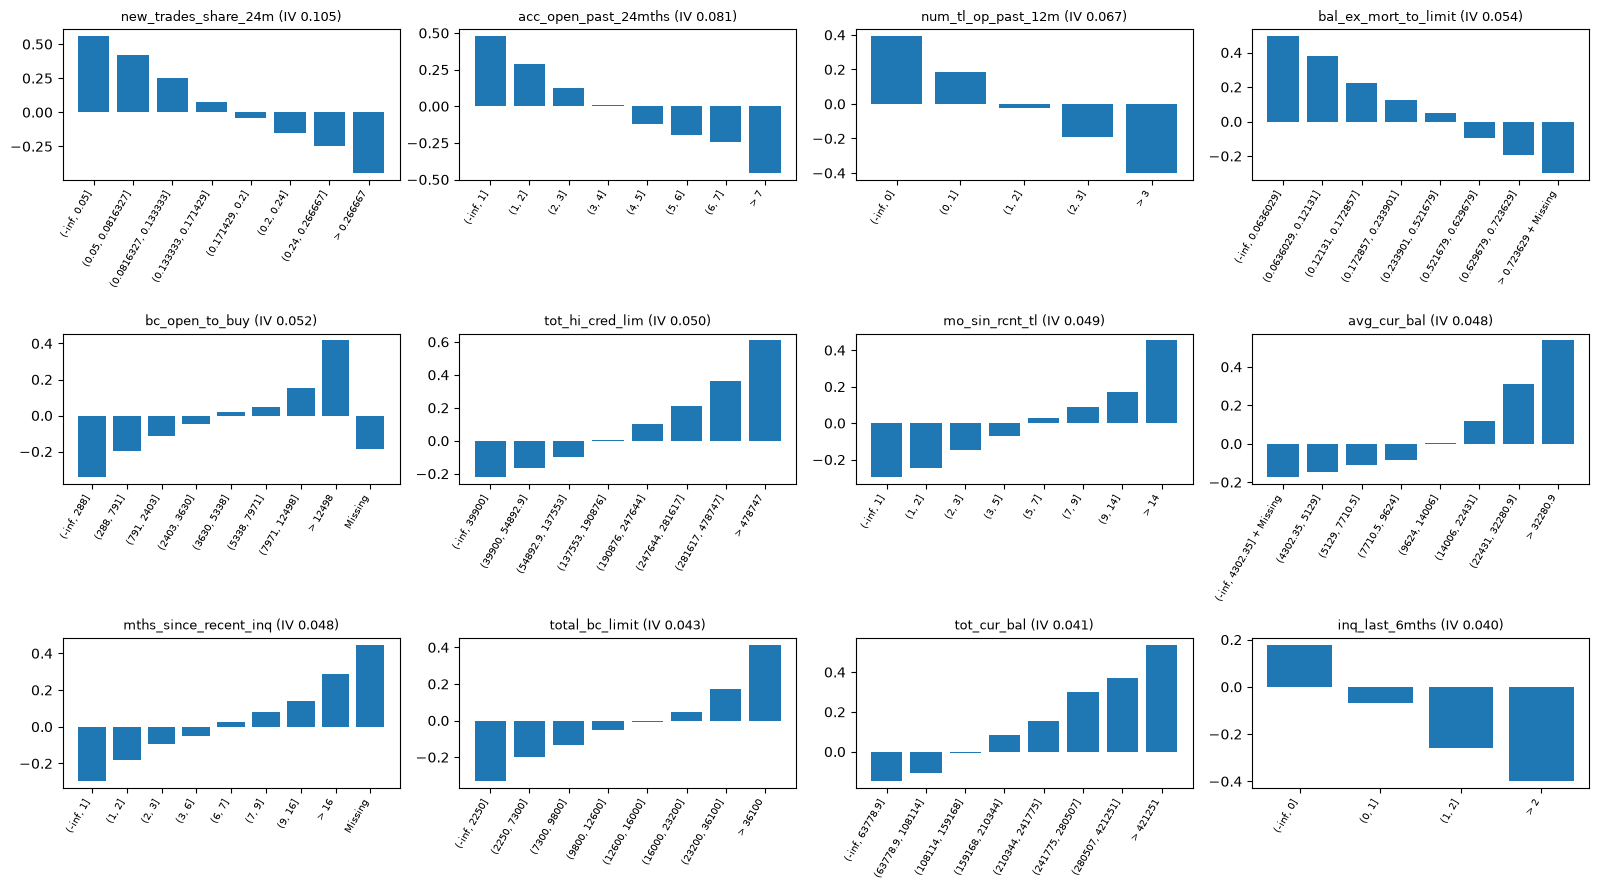

In [7]:
# Evidence — WOE by bin for the strongest attributes (tables and a plot each)
top = ivs.attribute.head(12).tolist()
for n in top:
    t = specs[n].table(); print(f"\n{n}  IV={specs[n].iv:.4f}  direction={specs[n].direction}  monotone={specs[n].monotone}  ({MEANINGS.get(n, '')})")
    display(t)
fig, axes = plt.subplots(3, 4, figsize=(16, 9)); axes = axes.ravel()
for ax, n in zip(axes, top):
    t = specs[n].table(); ax.bar(range(len(t)), t.woe); ax.set_xticks(range(len(t))); ax.set_xticklabels(t.label, rotation=60, ha="right", fontsize=7); ax.set_title(f"{n} (IV {specs[n].iv:.3f})", fontsize=9)
plt.tight_layout(); plt.show()

### Decision G — Overrides

Where a bin edge should sit on a business boundary (utilisation at 30/50/75/90, inquiries at 0/1/2/3+), or where the automatic merge produced a bin you cannot explain, set the edges by hand. Non-monotone shapes stay only with a documented reason.

**Your reasoning:**

**DECIDED 2026-10-31** (drafted by Claude from this notebook's full-data outputs, applied; pending final review by Siavash)

**No overrides proposed** (`OVERRIDES = {}`).

- The automatic edges are explainable.
- They already fall near business boundaries where those exist: `percent_bc_gt_75` at 0/25/40/50/66.7/75, `inq_last_6mths` at 0/1/2/>2, `num_tl_op_past_12m` at 0/1/2/3/>3.
- Every bin's WOE moves in the expected direction, so no non-monotone shape needs a written reason.

In [8]:
OVERRIDES = {
    # "revol_util": [30, 50, 75, 90],
    # "inq_last_6mths": [0, 1, 2],
}
for n, edges in OVERRIDES.items():
    specs[n] = B.fit_numeric_with_edges(tr[n], tr["bad"], edges, name=n, min_bads=PARAMS["min_bads"])
    print(n); display(specs[n].table())
ivs = B.iv_summary(specs)

In [9]:
# Evidence — stability of the bins across vintages (CSI of each attribute's bin shares vs train)
csi_tbl = B.csi_by_group(frame, specs, group_col="vintage_year")
display(csi_tbl.style.background_gradient(cmap="Reds", axis=None) if hasattr(csi_tbl, "style") else csi_tbl)
unstable = csi_tbl[(csi_tbl > 0.25).any(axis=1)].index.tolist()
print("attributes with CSI > 0.25 in some vintage:", unstable)

vintage_year,2013,2014,2015,2016
attribute,,,,
acc_open_past_24mths,0.011300,0.003600,0.019500,0.028800
avg_cur_bal,0.001600,0.000500,0.004600,0.002600
bal_ex_mort_to_limit,0.001800,0.000600,0.007200,0.006900
bc_open_to_buy,0.000600,0.000200,0.012000,0.046800
bc_util,0.004300,0.001300,0.017100,0.067400
credit_age_months,0.004900,0.001600,0.005400,0.012400
inq_last_6mths,0.000800,0.000300,0.042300,0.047100
mo_sin_old_il_acct,0.002900,0.001000,0.005500,0.012700
mo_sin_old_rev_tl_op,0.004800,0.001700,0.022400,0.049000


attributes with CSI > 0.25 in some vintage: []


### Decision H — IV cut and stability screen

Keep attributes above which IV? Drop those whose bins are unstable across vintages (a missing bin that disappears in 2016 is a structural gap, not consumer behaviour)? Attributes with IV above 0.5 are suspicious and need a leakage explanation.

**Your reasoning:**

**DECIDED 2026-10-31** (drafted by Claude from this notebook's full-data outputs, applied; pending final review by Siavash)

**Keep `MIN_IV = 0.02` and drop nothing for stability.**

**IV cut.** 19 of the 27 candidates have IV ≥ 0.02. The highest is `new_trades_share_24m` at 0.1048, far below the 0.5 that would suggest leakage. The 8 below the cut are dropped:

| Attribute | IV |
|---|---:|
| `mo_sin_old_il_acct` | 0.0177 |
| `revol_util` | 0.0126 |
| `revol_bal_to_limit` | 0.0123 |
| `revol_bal` | 0.0090 |
| `num_rev_tl_bal_gt_0` | 0.0083 |
| `num_bc_tl` | 0.0035 |
| `total_acc` | 0.0031 |
| `mths_since_last_record` | 0.0004 |

**Stability.** CSI against the train bins is below 0.10 for every attribute in every vintage, so nothing is dropped for instability.
- The highest values are in 2016: `percent_bc_gt_75` 0.0835, `revol_util` 0.0732, `revol_bal_to_limit` 0.0696, `bc_util` 0.0674, `num_bc_tl` 0.0636 and `new_trades_share_24m` 0.0503.
- The utilisation family drifts most toward 2016. NB09 should watch it.

In [10]:
MIN_IV = 0.02
DROP = list(unstable)            # edit: keep an unstable attribute only with a reason written above
final = [n for n in ivs[ivs.iv >= MIN_IV].attribute if n not in DROP]
B.save_specs({n: specs[n] for n in final}, MODELS / "bins.json")
(MODELS / "binning_decisions.json").write_text(json.dumps({"binned_attributes": final, "params": PARAMS, "overrides": OVERRIDES, "min_iv": MIN_IV, "dropped_unstable": DROP, "missing_own_bin": MISSING_OWN_BIN}, indent=1), encoding="utf-8")
ivs[ivs.attribute.isin(final)].to_csv(config.DOCS_DIR / "exhibits" / "iv_table.csv", index=False)
print(len(final), "attributes binned and saved to", MODELS / "bins.json")

19 attributes binned and saved to C:\Users\siava\OneDrive\Desktop\score-pilot-lab\models\bins.json
